# Vẽ quỹ đạo Gradient Descent trên đồ thị hàm mất mát một tham số (mục 5.1)

Hàm minh họa L(w) = w^2, khởi tạo w = 4, tốc độ học η = 0.2

w_t = [4.    2.4   1.44  0.864 0.518 0.311 0.187]


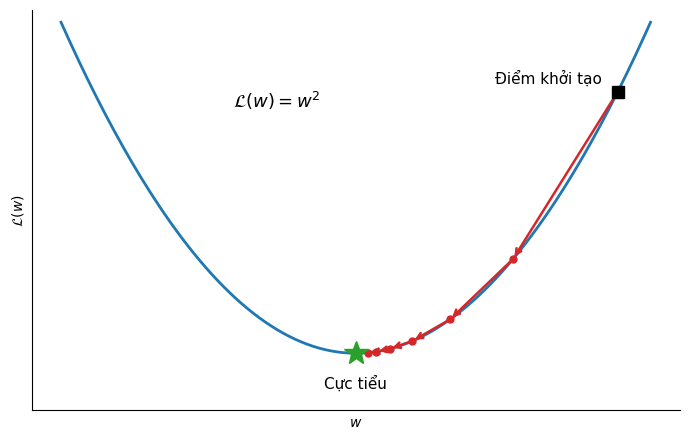

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def loss(w):
    """Hàm mất mát minh họa L(w)."""
    return w**2

def grad(w):
    """Đạo hàm dL/dw."""
    return 2 * w

eta = 0.2        # tốc độ học η
history = [4.0]  # dãy w_t, bắt đầu từ w = 4
for t in range(6):
    history.append(history[-1] - eta * grad(history[-1]))
history = np.array(history)
print('w_t =', np.round(history, 3))

w_grid = np.linspace(-4.5, 4.5, 200)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(w_grid, loss(w_grid), color='#1F77B4', lw=2)

# Mỗi mũi tên là một bước cập nhật
for start, end in zip(history[:-1], history[1:]):
    ax.annotate('', xy=(end, loss(end)), xytext=(start, loss(start)),
                arrowprops=dict(arrowstyle='->', color='#D62728', lw=1.8))
ax.plot(history, loss(history), 'o', color='#D62728', ms=5)
ax.plot(history[0], loss(history[0]), 's', color='black', ms=9, zorder=3)
ax.plot(0, 0, '*', color='#2CA02C', ms=18, zorder=3)

ax.text(3.75, 16.5, 'Điểm khởi tạo', fontsize=11, ha='right')
ax.text(0, -2.2, 'Cực tiểu', fontsize=11, ha='center')
ax.text(-1.2, 15, r'$\mathcal{L}(w) = w^2$', fontsize=13, ha='center')

# Bỏ vạch số: hình chỉ minh họa ý tưởng, không đọc giá trị
ax.set_xticks([]); ax.set_yticks([])
ax.set_ylim(-3.5, 21)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('$w$'); ax.set_ylabel(r'$\mathcal{L}(w)$')
fig.tight_layout()
fig.savefig(IMAGES / 'gd_trajectory.png', dpi=150)